# Finer than GRACE? Groundwater change by district and at 11 km

GRACE weighs the water in and under the land from orbit, but each of its "pixels" really sees a blur about 300 km
across. This notebook asks how far below that we can honestly go, with three tools:

1. **Wells** (CGWB, India): real measurements at points, summarised by district and smoothed into a surface.
2. **Statistical downscaling** of GRACE to 0.1° (~11 km) with satellite predictors, keeping GRACE's total water fixed.
3. **Testing both against the wells**, which the downscaling never sees.

Every number below is computed by the scripts in `src/` (steps 08 to 11) and read back here. Run order:

```
python src/08_fine_inputs.py      # predictors at 0.1 deg and district boundaries (Earth Engine)
python src/09_wells_fine.py       # wells by district, kriged surface, cross-validation
python src/10_downscale.py        # random forest downscaling + test on wells
python src/11_fine_qgis_prep.py   # layers for QGIS
"C:/Program Files/QGIS 4.2.3/bin/python-qgis.bat" src/07_qgis_project.py
```

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr, geopandas as gpd, matplotlib.pyplot as plt
R = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
P, OUT, Q = R / "data/processed", R / "outputs/fine", R / "outputs/qgis"
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10})
EXT = [60, 105, 5, 40]

## 1. The predictors: what can see finer than GRACE?
Groundwater loss in South Asia is mostly pumping for irrigation, so the predictors are things that track irrigation
and its water use at 1 km or finer, averaged to 0.1° cells: dry-season greenness (crops in January-April are almost
always irrigated), its trend, cropland share, evapotranspiration, rainfall and its trend, dry-season land temperature,
population, elevation and slope.

<xarray.Dataset> Size: 6MB
Dimensions:         (lat: 350, lon: 450)
Coordinates:
  * lat             (lat) float64 3kB 39.95 39.85 39.75 39.65 ... 5.25 5.15 5.05
  * lon             (lon) float64 4kB 60.05 60.15 60.25 ... 104.8 104.8 105.0
Data variables:
    ndvi_dry        (lat, lon) float32 630kB ...
    ndvi_dry_trend  (lat, lon) float32 630kB ...
    cropland        (lat, lon) float32 630kB ...
    et              (lat, lon) float32 630kB ...
    precip          (lat, lon) float32 630kB ...
    precip_trend    (lat, lon) float32 630kB ...
    lst_dry         (lat, lon) float32 630kB ...
    pop             (lat, lon) float32 630kB ...
    elev            (lat, lon) float32 630kB ...
    slope           (lat, lon) float32 630kB ...
Attributes:
    note:     0.1 deg means of source pixels, 2003-2024; see src/08_fine_inpu...


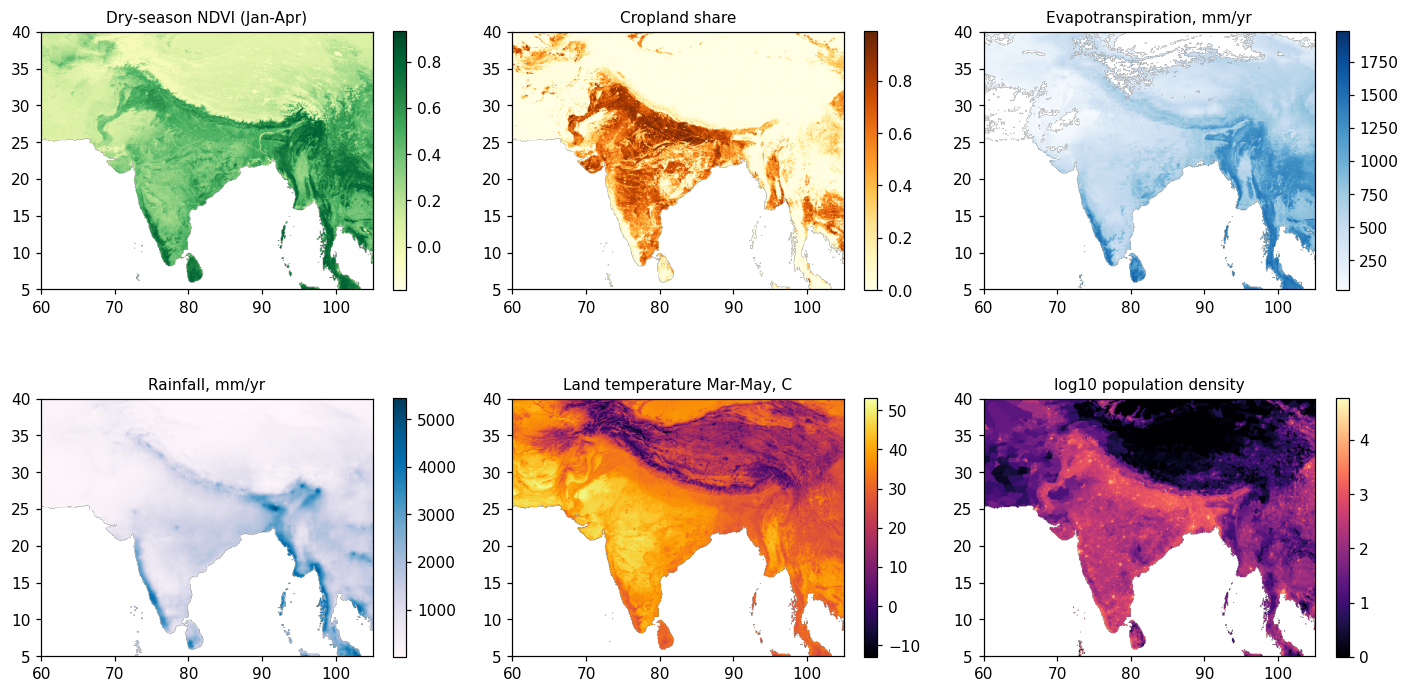

In [2]:
F = xr.open_dataset(P / "fine_predictors_0p1.nc")
print(F)
fig, ax = plt.subplots(2, 3, figsize=(13, 7))
for a, (k, cm, lab) in zip(ax.flat, [("ndvi_dry", "YlGn", "Dry-season NDVI (Jan-Apr)"), ("cropland", "YlOrBr", "Cropland share"),
                                     ("et", "Blues", "Evapotranspiration, mm/yr"), ("precip", "PuBu", "Rainfall, mm/yr"),
                                     ("lst_dry", "inferno", "Land temperature Mar-May, C"), ("pop", "magma", "log10 population density")]):
    im = a.imshow(F[k], extent=EXT, cmap=cm); a.set_title(lab); fig.colorbar(im, ax=a, shrink=.7)
plt.tight_layout()

## 2. Wells by district
CGWB measures depth to water in about 10,000 wells. For each well with at least 5 May readings in 2013-2020 we fit a
slope (metres per year, positive = falling). Districts with at least 5 wells get the median slope, and a storage change
= slope × specific yield (how much water a metre of aquifer releases: 0.08-0.16 in alluvium, 0.01-0.03 in hard rock).

In [3]:
wd = pd.read_csv(OUT / "wells_districts.csv")
print(f"{len(wd)} districts with >= 5 wells; wells per district: median {wd.wells.median():.0f}, range {wd.wells.min()}-{wd.wells.max()}")
print("share of districts where the median well is falling (> 0.1 m/yr):", round((wd.slope_median_m_yr > 0.1).mean(), 2))
wd.sort_values("storage_mid_cm_yr").head(10)[["ADM1_NAME", "ADM2_NAME", "wells", "slope_median_m_yr", "share_falling", "storage_lo_cm_yr", "storage_hi_cm_yr"]]

383 districts with >= 5 wells; wells per district: median 20, range 5-95
share of districts where the median well is falling (> 0.1 m/yr): 0.64


,ADM1_NAME,ADM2_NAME,wells,slope_median_m_yr,share_falling,storage_lo_cm_yr,storage_hi_cm_yr
27,Rajasthan,Dausa,7,1.6751,1.0000,-26.8023,-13.4011
148,Rajasthan,Alwar,22,1.6195,1.0000,-25.9114,-12.9557
160,Rajasthan,Jhunjhunun,11,1.4029,0.8182,-22.4457,-11.2229
146,Punjab,Sangrur,13,1.3834,1.0000,-22.1349,-11.0674
164,Rajasthan,Sikar,27,1.1829,0.9630,-18.9257,-9.4629
24,Punjab,Moga,6,0.9854,1.0000,-15.7669,-7.8834
1,Haryana,Kurukshetra,16,0.9754,0.8750,-15.6069,-7.8034
11,Punjab,Patiala,18,0.8959,0.7778,-14.3337,-7.1669
7,Rajasthan,Dhaulpur,10,0.8514,0.8000,-13.6229,-6.8114
3,Haryana,Kaithal,11,0.8474,1.0000,-13.5589,-6.7794


wells_vs_grace
both losing                205
GRACE losing, wells not     85
wells losing, GRACE not     51
neither losing              42
Name: count, dtype: int64


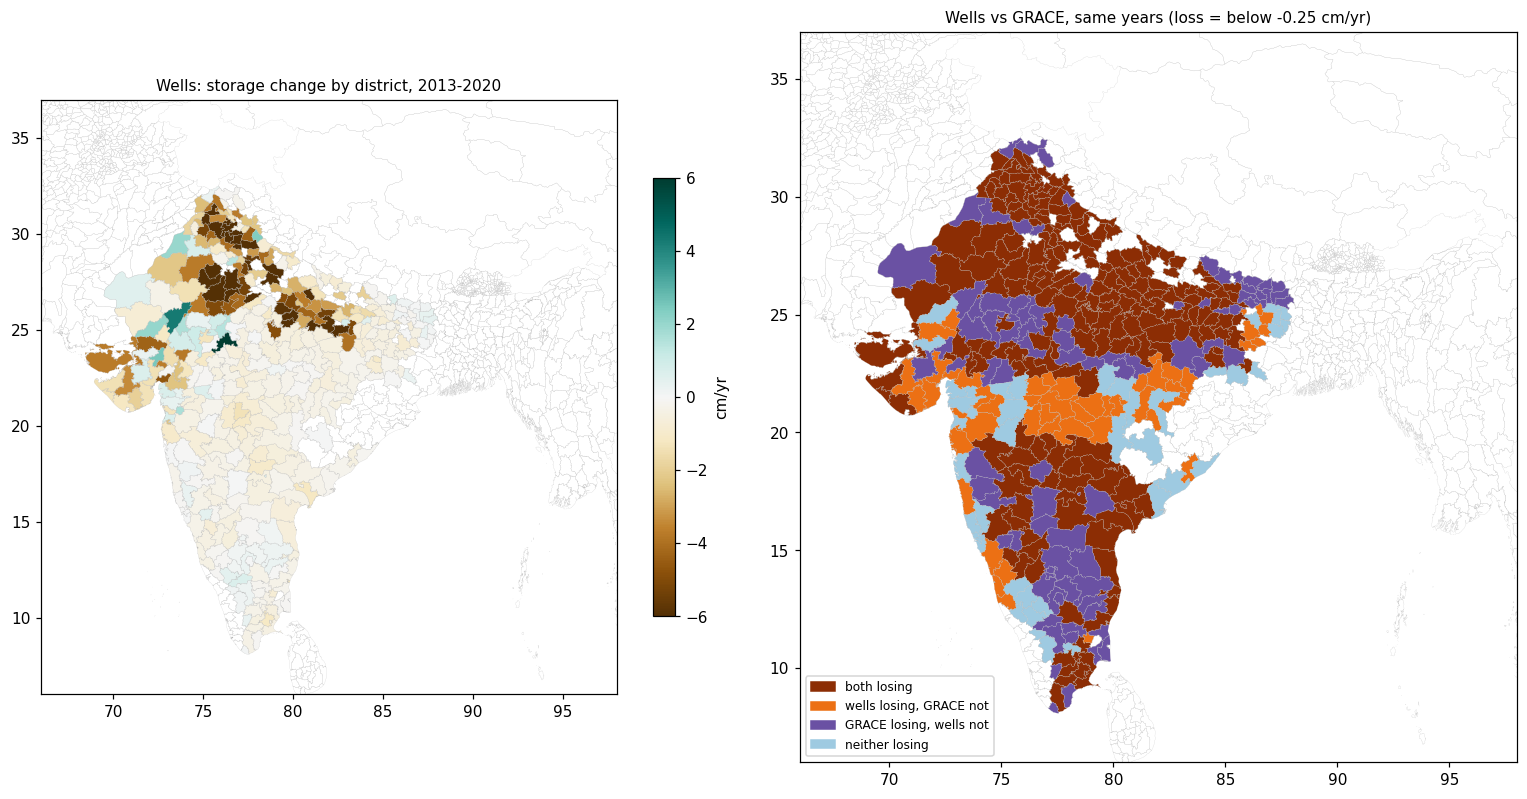

In [4]:
d = gpd.read_file(Q / "fine.gpkg", layer="districts")
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
d.boundary.plot(ax=ax[0], lw=.1, color="0.7")
d[d.wells.notna()].plot(column="storage_mid_cm_yr", ax=ax[0], cmap="BrBG", vmin=-6, vmax=6, legend=True, legend_kwds={"shrink": .6, "label": "cm/yr"})
ax[0].set_title("Wells: storage change by district, 2013-2020"); ax[0].set_xlim(66, 98); ax[0].set_ylim(6, 37)
cols = {"both losing": "#8c2d04", "wells losing, GRACE not": "#ec7014", "GRACE losing, wells not": "#6a51a3", "neither losing": "#9ecae1"}
d.boundary.plot(ax=ax[1], lw=.1, color="0.7")
for k, c in cols.items():
    d[d.wells_vs_grace == k].plot(ax=ax[1], color=c, label=k)
ax[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in cols.values()], labels=list(cols), loc="lower left", fontsize=8)
ax[1].set_title("Wells vs GRACE, same years (loss = below -0.25 cm/yr)"); ax[1].set_xlim(66, 98); ax[1].set_ylim(6, 37)
plt.tight_layout(); print(d.wells_vs_grace.value_counts())

Most districts with wells agree with GRACE that water is being lost. Where wells fall but GRACE does not, the loss is
local: a few districts losing water inside a 300 km blur that also contains stable or recovering land.

## 3. A surface from the wells (kriging), and how much to trust it
To fill the gaps between wells, the slopes are binned to 0.1° cells and interpolated by ordinary kriging. Then the
honest question: if we hide some wells, does the surface predict them? Two tests, both 5-fold: hide whole 2° blocks
(far from any used well), or hide random cells (with neighbours still present).

In [5]:
pd.read_csv(OUT / "wells_krige_cv.csv")

,test,cells,rmse_krige_m_yr,rmse_mean_m_yr,skill_vs_mean,spearman,sign_agreement
0,blocked 2 deg,7033,0.650,0.655,0.014,0.205,0.674
1,random cells,7033,0.651,0.654,0.009,0.298,0.676


Both tests give a skill near zero against simply using the average well (`skill_vs_mean`), and a weak rank
correlation (0.2-0.3). **One well's trend is mostly local**: pumping at and around that well, its depth, the aquifer
layer it taps. A neighbouring well 10 km away says little about it. So the kriged surface in QGIS is a *smoothed
tendency*, drawn only within 30 km of wells, with its uncertainty layer beside it, and the district medians (many wells
each) are the trustworthy fine-scale product.

## 4. Downscaling GRACE to 0.1°
A random forest learns how the GRACE trend of each 0.5° cell relates to the predictors averaged over that cell, then
predicts at 0.1°. Each 0.5° cell's 25 fine values are then shifted so that their mean is exactly GRACE's: water is
moved around inside a cell, never created. Skill at 0.5° is tested by hiding 5° blocks.

In [6]:
sk = pd.read_csv(OUT / "downscale_skill.csv"); sk

,period,cells_0p5,cv_r2_0p5,level,n,spearman_downscaled,spearman_plain_grace
0,whole,3793.0,0.221,NaN,NaN,NaN,NaN
1,2013_2020,3793.0,0.268,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,0.1 deg cells with wells,6881.0,0.082,0.076
3,NaN,NaN,NaN,"within GRACE cells (anomalies, cells with >= 4...",6604.0,0.030,0.000
4,NaN,NaN,NaN,districts with >= 5 wells,382.0,0.447,0.437
5,NaN,NaN,NaN,"within GRACE cells, model trained on wells (2 ...",6704.0,-0.001,0.000


Text(0.5, 1.0, 'What the forest uses (whole record)')

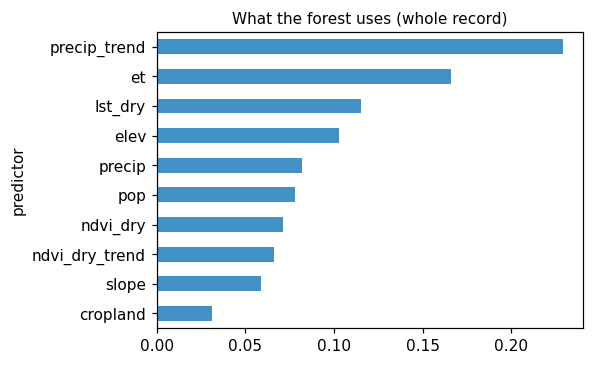

In [7]:
imp = pd.read_csv(OUT / "downscale_importance.csv")
ax = imp.plot.barh(x="predictor", y="importance", legend=False, figsize=(5, 3.5), color="#4292c6"); ax.invert_yaxis(); ax.set_title("What the forest uses (whole record)")

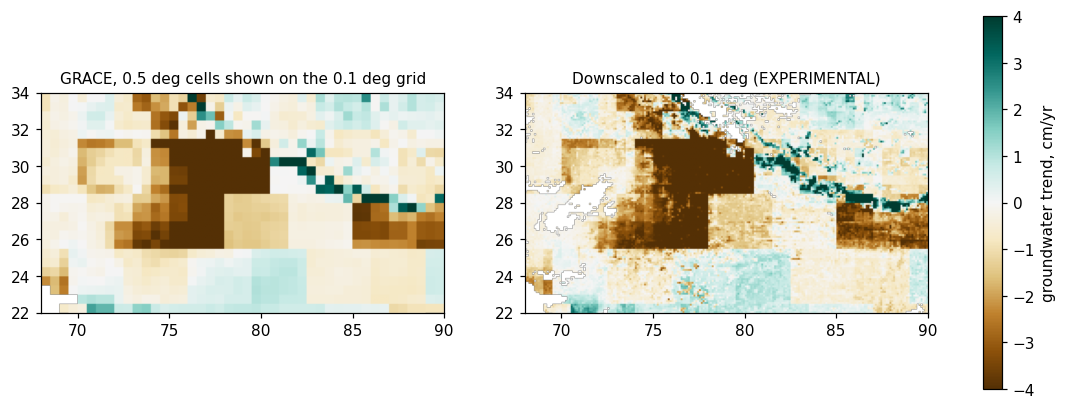

In [8]:
D = xr.open_dataset(P / "gwsa_trend_0p1.nc")
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, (v, t) in zip(ax, [("grace_plain_whole", "GRACE, 0.5 deg cells shown on the 0.1 deg grid"), ("gwsa_trend_whole", "Downscaled to 0.1 deg (EXPERIMENTAL)")]):
    im = a.imshow(D[v], extent=EXT, cmap="BrBG", vmin=-4, vmax=4); a.set_xlim(68, 90); a.set_ylim(22, 34); a.set_title(t)
fig.colorbar(im, ax=ax, shrink=.8, label="groundwater trend, cm/yr"); plt.show()

Look at the left panel: the large rectangles are JPL's 3° mascons, the blocks GRACE actually solves for. The 0.5°
grid only resamples them. That is GRACE's real resolution, drawn.

The downscaled map looks sharper. Looking sharper is not the same as being right, so:

## 5. The test: do the wells agree with the extra detail?
The rows of the table above beyond the first two compare, by rank correlation, the 2013-2020 trends with the wells,
for the downscaled map and for plain GRACE:
- **0.1° cells with wells**: downscaled 0.08 vs plain GRACE 0.08.
- **districts**: 0.45 vs 0.44.
- **within GRACE cells** (the detail itself: inside one 0.5° cell, are the fine cells the model calls worse the ones
  where wells fall faster?): 0.03, essentially none.

A second attempt trained the within-cell pattern on the wells themselves, with 2° blocks held out: rank correlation
-0.001. With these predictors, **the variation of groundwater loss inside a GRACE cell cannot be recovered**. The
forest's skill at 0.5° (R² 0.2-0.3) comes from large-scale gradients, mainly the rainfall trend, not from where pumping
is heavier within a cell.

What this means for the maps:
- **GRACE by district** is honest but carries no information finer than ~300 km; neighbouring districts share values.
- **Wells by district** is real detail, for India (Pakistan and Bangladesh need their well data: see
  `docs/data_requests.md`).
- **Downscaled** layers are kept, switched off and labelled experimental, so the method can be improved and re-tested
  (better irrigation-source maps, canal command areas, aquifer type, InSAR).

## 6. In QGIS
`outputs/qgis/groundwater.qgz` now has two new groups:
- **Districts: finer detail**: district boundaries (labels appear when zoomed in), wells by district, wells vs GRACE,
  GRACE by district, and the experimental downscaled districts. Click a district to see every number.
- **Fine grids, 0.1°**: kriged well trend and its uncertainty, GRACE on the 0.1° grid, and the experimental downscaled grid.

In [9]:
import sqlite3
print([r[0] for r in sqlite3.connect(Q / "fine.gpkg").execute("select table_name from gpkg_contents")])
d.drop(columns="geometry").dropna(subset=["wells"]).sort_values("storage_mid_cm_yr").head(5)[
    ["ADM1_NAME", "ADM2_NAME", "wells", "storage_mid_cm_yr", "grace_2013_2020_cm_yr", "wells_vs_grace"]]

['districts']


,ADM1_NAME,ADM2_NAME,wells,storage_mid_cm_yr,grace_2013_2020_cm_yr,wells_vs_grace
126,Rajasthan,Dausa,7.0,-20.102,-6.806,both losing
330,Rajasthan,Alwar,22.0,-19.434,-6.557,both losing
342,Rajasthan,Jhunjhunun,11.0,-16.834,-4.174,both losing
328,Punjab,Sangrur,13.0,-16.601,-7.454,both losing
346,Rajasthan,Sikar,27.0,-14.194,-4.105,both losing


## 7. What would really add resolution
- **More wells**: Punjab (Pakistan) Irrigation Department piezometers and Bangladesh BWDB wells; the same district
  method then covers the Indus and the Bengal delta.
- **InSAR subsidence** (Sentinel-1, ~100 m): sinking ground shows where aquifers are being drained, at the scale of
  a town. Already done for Karachi; Lahore, Quetta and the Delhi-Haryana belt are next candidates.
- **Better pumping predictors**: maps of groundwater- vs canal-irrigated land, electricity use for pumps, tube-well
  counts by district (agricultural census). These are what the forest lacked.